# Orbital Pruning with `sisl`: a beginner's tutorial

This tutorial introduces the basic ingredients for pruning orbitals in **sisl**.
The tutorial is divided into two parts:

1. **Nanoporous graphene (NPG): from DFT to a reduced $p_z$ Hamiltonian.** We read a precomputed SIESTA Hamiltonian, inspect its band structure, keep only the carbon and nitrogen $p_z$ orbitals, compare the reduced model with the original DFT bands, visualize selected wave functions, and calculate the transmission along the conducting direction.

2.  **STO**: Systems such as SrTiO$_3$ (STO) exhibit complex band structures, in which the electronic states generally arise from linear combinations of several atomic orbitals. Unlike in graphene or nanoporous graphene (NPG), where a simplified description can be obtained by retaining only the $p_z$ orbitals, the electronic structure of STO cannot be accurately captured using a single orbital type. Instead, the choice of orbitals must be adapted to the bands of interest, whether they belong to the valence band, the conduction band, or another selected subset of bands.
Note that, since we are now considering bulk STO, it is essential to preserve the symmetries of the bulk crystal when selecting the orbital basis. This requires retaining complete sets of symmetry-related orbitals, such as the $p$ orbitals $(p_x,p_y,p_z)$ or the $t_{2g}$ orbitals $(d_{xy},d_{yz},d_{zx})$.

Tutorial made by Niels Gabriel and Alan Anaya

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from tqdm.notebook import tqdm

import sisl as si

si.__version__  # this tutorial is written for sisl 0.20.0

'0.20.0'

In [2]:
# Plot settings used throughout the tutorial.
# All plots (also the sisl ones, drawn with backend="matplotlib") follow these settings.
plt.rcParams.update(
    {
        "figure.figsize": (4, 6),  # default size, suited for band structures
        "font.size": 12,
        "axes.labelsize": 14,
        "axes.titlesize": 16,
        "legend.framealpha": 1,
    }
)


def compare_bands(bs_ref, bs_pruned, Erange, labels=("DFT", "pruned")):
    """Overlay the bands of the original (black) and the pruned (red, dashed) Hamiltonian

    Both band structures must use the same k-path.
    """
    x, ticks, tick_labels = bs_ref.lineark(ticks=True)
    fig, ax = plt.subplots()
    for bs, style, label in [(bs_ref, "k-", labels[0]), (bs_pruned, "r--", labels[1])]:
        lines = ax.plot(x, bs.apply.array.eigh(), style, lw=2)
        lines[0].set_label(label)  # a single legend entry per band structure
    for tick in ticks:
        ax.axvline(tick, color="k", lw=0.3)
    ax.axhline(0, color="k", lw=0.3)
    ax.set_xticks(ticks, tick_labels)
    ax.set(xlim=(ticks[0], ticks[-1]), ylim=Erange, ylabel=r"$E-E_F$ [eV]")
    ax.legend(loc="center right")


def valence_band_top(H):
    """Highest occupied eigenvalue at the Γ point (energies are relative to E_F)"""
    eig = H.eigh()
    return eig[eig < 0].max()

# I. Nanoporous graphene: reducing a DZP Hamiltonian to a $p_z$ model

## 1. Read the SIESTA Hamiltonian

We begin with a **precomputed DFT Hamiltonian from SIESTA**. `sisl` can read the Hamiltonian directly from the SIESTA input/output files. The resulting object contains both the atomic geometry and the Hamiltonian/overlap matrices needed for the following analysis.

In [3]:
# Read the Hamiltonian (and overlap matrix, geometry and basis) from the SIESTA run
H_dft = si.get_sile("NPG_DZP/RUN.fdf").read_hamiltonian()

Before doing any electronic-structure or transport calculation, it is useful to inspect the geometry. Here we use `sisl`'s plotting tools to visualize the nanoporous graphene (NPG) structure.

The NPG consists of laterally connected graphene nanoribbons (GNRs). In this example, every second GNR is chemically modified with nitrogen atoms at the bridges.

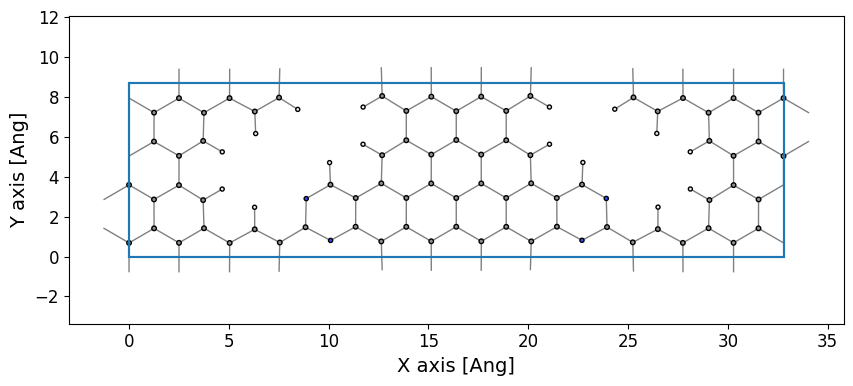

In [4]:
geom_plot = H_dft.geometry.plot(axes="xy", backend="matplotlib")
geom_plot.set_size_inches(10, 4)

The same geometry can also be converted to an ASE `Atoms` object and opened with an ASE-compatible viewer. This is useful for interactive inspection of larger structures.

```python
from ase.visualize import view
view(H_dft.to.ase())
```
We won't do it here, but for you to know.

## 2. Calculate the band structure and fatbands
Next we calculate the **band structure** of the original DFT Hamiltonian. A band-structure calculation requires a path through reciprocal space and a number of $k$ points along that path. Here the path is $X \rightarrow\Gamma\rightarrow Y$.

In [5]:
# k-path (in units of the reciprocal lattice vectors) and the total number of k points on it
kpath = [[0.5, 0, 0], [0, 0, 0], [0, 0.5, 0]]
klabels = [r"$X$", r"$\Gamma$", r"$Y$"]
nk = 30
bs = si.BandStructure(H_dft, kpath, nk, klabels)

In [ ]:
bands = bs.plot.bands(Erange=(-1.5, 1.5), backend="matplotlib")
bands.legend()

To see which orbitals make up these bands, we plot **fatbands**: the bands are weighted by their projection onto a group of orbitals.

The NPG unit cell contains two GNRs: atoms 0–49 belong to the pristine GNR (carbon and hydrogen) and atoms 50–95 to the N-doped GNR.
We project the bands onto the $2p_z$ orbitals (first zeta, named `2pzZ1` in the SIESTA basis) of the carbon and nitrogen atoms in each GNR.
In `sisl`, each group is a *query* combining e.g. `atoms`, `species` and `orbitals` (orbital names).

In [7]:
groups = [
    {"name": r"pristine GNR $p_z$", "atoms": range(50), "species": ["C"], "orbitals": ["2pzZ1"], "color": "red"},
    {"name": r"N-doped GNR $p_z$", "atoms": range(50, 96), "species": ["C", "N"], "orbitals": ["2pzZ1"], "color": "blue"},
]
fatbands = bs.plot.fatbands(groups=groups, Erange=(-2, 2), fatbands_scale=0.1, backend="matplotlib")
fatbands.legend();

As you can see the VB and CB have majority contribution from the $p_z$ orbitals 

## 3. Keep only the $p_z$ orbitals

The full DZP basis contains several atomic orbitals per atom. For the low-energy $\pi$ bands of graphene-like systems, the dominant contribution usually comes from the out-of-plane $p_z$ orbitals.

We therefore construct a reduced, tight-binding-like Hamiltonian by keeping only the carbon and nitrogen $p_z$ orbitals.

In [8]:
# Orbitals (by name) of each species in the DZP basis
for atom in H_dft.atoms.atom:
    print(f"{atom.symbol}:", [orb.name() for orb in atom])

`sub` can be used to keep a selected subset of atoms, while `sub_orbital` keeps selected orbitals on those atoms.

First we retain only the carbon and nitrogen atoms (`atoms.index` finds the atoms of the given elements). We then retain only the `2pzZ1` orbital, which was identified above as the relevant $p_z$ orbital for this basis; `atom.index(name)` converts an orbital name to its index in the basis of that atom. The result is a much smaller Hamiltonian that is easier to analyze and use in transport calculations.

In [9]:
keep = ["2pzZ1"]  # names of the orbitals to keep on C and N

H_tb = H_dft.sub(H_dft.atoms.index(["C", "N"]))
for atom in (H_dft.atoms["C"], H_dft.atoms["N"]):
    H_tb = H_tb.sub_orbital(atom, [atom.index(name) for name in keep])

print(f"DFT:     {H_dft.na} atoms, {H_dft.no} orbitals")
print(f"pruned:  {H_tb.na} atoms, {H_tb.no} orbitals")

After pruning the basis, the absolute energy reference of the reduced Hamiltonian does not necessarily coincide with that of the original DFT Hamiltonian. We therefore apply a rigid energy shift so that the valence-band edge of the reduced model aligns with the corresponding DFT state.

In [10]:
eshift = valence_band_top(H_dft) - valence_band_top(H_tb)
H_tb.shift(eshift)
print("Energy shift:", eshift)

In [11]:
bs_tb = si.BandStructure(H_tb, kpath, nk, klabels)
compare_bands(bs, bs_tb, Erange=(-1.5, 1.5), labels=("DZP", r"$p_z$ TB"))

## 4. Visualize selected electronic states

We now use the reduced $p_z$ Hamiltonian to visualize the states at the valence- and conduction-band edges at $\Gamma$. `sisl` evaluates the eigenstate wave function on a real-space grid, which allows us to see where the selected state is localized within the NPG unit cell.

Since a $p_z$ orbital has a node in the plane of the atoms, we show the wave function averaged over a slab 0.5–1 Å above the NPG plane.

In [12]:
es = H_tb.eigenstate(dtype=np.float64)  # all eigenstates at Γ (real wave functions)
iVB = np.count_nonzero(es.eig < 0) - 1  # index of the highest occupied state
z = H_tb.geometry.xyz[0, 2]  # height of the NPG plane

for name, i in [("VB", iVB), ("CB", iVB + 1)]:
    wf = es.plot.wavefunction(
        i=i, grid_prec=0.2, axes="xy", z_range=(z + 0.5, z + 1),
        nsc=(3, 6, 1), plot_geom=True, colorscale="coolwarm", crange=(-0.25, 0.25),
        backend="matplotlib",
    )
    wf.set_size_inches(12, 6)
    wf.set_title(rf"{name} $\psi$ (E = {es.eig[i]:.2f} eV)")

## 5. Transmission along the NPG

In this exercise, we calculate the transport along the **$y$ direction**, corresponding here to lattice vector `B` (axis `1` in `sisl`). The NPG unit cell is repeated three times along this direction to form a finite device containing a left, central, and right cell.

### Partitioning of the Hamiltonian and the Caroli formula

In quantum transport calculations, we describe an electronic device as a finite central scattering region connected to two semi-infinite electrodes. The electrodes act as electron reservoirs, allowing electrons to enter and leave the device.

$$
\boldsymbol H =
\begin{pmatrix}
\boldsymbol H_L & \boldsymbol V_{LC} & \boldsymbol 0 \\
\boldsymbol V_{CL} & \boldsymbol H_D & \boldsymbol V_{CR} \\
\boldsymbol 0 & \boldsymbol V_{RC} & \boldsymbol H_R
\end{pmatrix}.
$$

Here, $\boldsymbol H_L$ and $ \boldsymbol H_R$ describe the semi-infinite electrodes, $\boldsymbol H_D$ describes the finite device, and $ \boldsymbol V_{\alpha\beta}$ describes the coupling between different regions.

![title](./Figures/Device.webp)

For coherent two-terminal transport, the energy- and $k$-resolved transmission is calculated with the Caroli expression

$$T(E,k)=\mathrm{Tr}\left[\boldsymbol\Gamma_L\,\mathbf G^r\,\boldsymbol\Gamma_R\,\mathbf G^a\right],$$

where $\mathbf G^a=(\mathbf G^r)^\dagger$ and

$$\boldsymbol\Gamma_\alpha=i\left(\boldsymbol\Sigma_\alpha-\boldsymbol\Sigma_\alpha^\dagger\right)$$

describes the broadening produced by electrode $\alpha$. The retarded Green function of the open device is

$$\mathbf G^r(E,k)=\left[(E+i\eta)\mathbf S_k-\mathbf H_k-\boldsymbol\Sigma_L(E,k)-\boldsymbol\Sigma_R(E,k)\right]^{-1}.$$

Here $\mathbf H_k$ and $\mathbf S_k$ are the Hamiltonian and overlap matrices at the transverse $k$ point, and $\eta>0$ is a small numerical broadening.

Because the transport direction is now treated as an open direction connected to semi-infinite electrodes, periodicity along $y$ is removed from the finite device by setting the number of supercells in that direction to one.

In [13]:
# Device: 3 NPG unit cells along y (lattice vector B)
H_device = H_tb.tile(3, 1)
# The y direction is now open (replaced by the electrodes): no periodic images along B
H_device.set_nsc(b=1)

device_plot = H_device.geometry.plot(axes="xy", backend="matplotlib")
device_plot.set_size_inches(8, 6)

### Recursive method for calculating the self energies

For a semi-infinite electrode with nearest-neighbor cell coupling, the Hamiltonian has the form

$$
\boldsymbol H_L =
\begin{pmatrix}
\ddots & \ddots & 0 & 0 \\
\ddots &\boldsymbol  H_0 & \boldsymbol V^\dagger & 0 \\
0 & \boldsymbol V & \boldsymbol H_0 &\boldsymbol  V^\dagger \\
0 & 0 & \boldsymbol V & \boldsymbol H_0
\end{pmatrix},
$$

where $\boldsymbol H_0$ is the Hamiltonian of the cell and $\boldsymbol V$ describes the coupling between adjacent cells.

Rather than directly inverting an infinite-dimensional Hamiltonian, we calculate the **surface Green function** using a recursive technique.

For a detailed discussion of the recursive method, see
M. P. López Sancho, J. M. López Sancho, and J. Rubio. Journal of Physics F: Metal Physics 15, 851 (1985).

For an orthogonal tight-binding Hamiltonian, the surface Green function satisfies the self-consistent equation

$$
\mathbf g^r(E) = \left[(E+i\eta) - \boldsymbol H_0 - \boldsymbol V \mathbf g^r(E) \boldsymbol V^\dagger\right]^{-1},
$$

which the recursive method solves by repeatedly *decimating* every second cell:

![title](./Figures/Recursive.png)

The effects of the semi-infinite electrodes are incorporated through their retarded self-energies:

$$
\boldsymbol \Sigma_L^r(E) = \boldsymbol V_{CL}\boldsymbol  g_L^r(E) \boldsymbol V_{LC},
$$

$$
\boldsymbol \Sigma_R^r(E) =\boldsymbol  V_{CR} \boldsymbol g_R^r(E)  \boldsymbol V_{RC},
$$

where $\boldsymbol g_L^r$ and $\boldsymbol g_R^r$ are the surface Green functions of the electrodes.

In `sisl`, this calculation can be performed using `RecursiveSI`, which provides the electrode self-energy by using the Lopez-Sancho recursive method.

For transport in NPG along **y**, we use `-B` and `+B` to select semi-infinite electrodes extending in the negative and positive directions of lattice vector `B`, respectively.

In [14]:
eta = 1e-4  # small numerical broadening [eV]
SE_bottom = si.RecursiveSI(H_tb, "-B", eta=eta)
SE_top = si.RecursiveSI(H_tb, "+B", eta=eta)

### Energy and transverse-$k$ grids

The NPG is still periodic in the transverse **$x$ direction**. Therefore the transmission depends on the transverse Bloch vector $k_x$, and the physically relevant transmission is obtained by a weighted Brillouin-zone average,

$$
T(E)=\sum_{k_x} w_{k_x}T(E,k_x).
$$

The number of transverse points `nkx` should be increased until the averaged transmission is converged.

`En` defines the energy grid and `MonkhorstPack(..., [nkx, 1, 1])` samples only the transverse $x$ direction. The transport direction itself is not sampled because it has been opened and replaced by the two semi-infinite electrode self-energies.

In [15]:
nkx = 1
bz = si.MonkhorstPack(H_tb, [nkx, 1, 1])
En = np.linspace(-1, 1, 21)  # energy grid [eV], dE = 0.1 eV

# Device orbitals coupled to the bottom (first cell) and top (last cell) electrodes
idx_bottom = np.arange(H_tb.no)
idx_top = idx_bottom + 2 * H_tb.no

### Green-function loop

For every transverse $k_x$, the device Hamiltonian and overlap are evaluated at that same $k$ point. The electrode self-energies must use the same $k_x$. The function below calculates the device Green function and the electrode broadening matrices at a given energy and $k_x$; it is reused for the bond currents further below.
The loop then evaluates $T(E,k_x)$ for each energy and stores it before performing the weighted $k_x$ average.

In [ ]:
def device_green(E, k):
    """Retarded Green function of the device and the broadening matrices of both electrodes"""
    Sigma_B = SE_bottom.self_energy(E, k=k)
    Sigma_T = SE_top.self_energy(E, k=k)

    # G^-1 = (E + i eta) S - H - Sigma_B - Sigma_T
    G_inv = (E + 1j * eta) * H_device.Sk(k=k, format="array") - H_device.Hk(k=k, format="array")
    G_inv[np.ix_(idx_bottom, idx_bottom)] -= Sigma_B
    G_inv[np.ix_(idx_top, idx_top)] -= Sigma_T

    Gamma_B = 1j * (Sigma_B - Sigma_B.conj().T)
    Gamma_T = 1j * (Sigma_T - Sigma_T.conj().T)
    return np.linalg.inv(G_inv), Gamma_B, Gamma_T


T_k = np.zeros((len(bz), len(En)))
for ik, k in enumerate(bz.k):
    for iE, E in enumerate(tqdm(En, desc=f"k = {k}", leave=False)):
        G, Gamma_B, Gamma_T = device_green(E, k)
        G_BT = G[np.ix_(idx_bottom, idx_top)]
        T_k[ik, iE] = np.trace(Gamma_B @ G_BT @ Gamma_T @ G_BT.conj().T).real

# Brillouin-zone average over the transverse k points
T = bz.weight @ T_k

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(En, T, "ko-")
ax.set(xlabel="Energy [eV]", ylabel="Transmission", xlim=(En[0], En[-1]), ylim=(0, None));

For an ideal ballistic conductor, the transmission at each fixed $k_x$ equals the number of propagating channels:

$$
T(E,k_x)=N_{\mathrm{channels}}(E,k_x).
$$

### Visualizing the bond current

Physically, the spectral function

$$\boldsymbol A_{L}(E) = \mathbf G^r \boldsymbol\Gamma_L \mathbf G^a$$

describes the spectral weight in the device associated with electronic states injected from the left electrode (here: the bottom electrode, `B`).

For an orthogonal tight-binding Hamiltonian, the bond-resolved spectral transmission from orbital $i$ to orbital $j$ can be written, with the convention used below, as
$$
\boldsymbol J_{i\rightarrow j}^{({L,R})}(E,k_x)
=-2\,\operatorname{Im}
\left[
\boldsymbol (H_{ij}(k_x)-E \boldsymbol S_{ij}(k_x))A_{ji}^{({L,R)}}(E,k_x)
\right].$$

In the $p_z$ model each atom carries a single orbital, so orbital indices are also atom indices. We only show the currents along nearest-neighbor bonds (atoms closer than 1.7 Å).

In [ ]:
E0 = 0.25  # energy [eV]
k = bz.k[0]  # selected transverse k-point

G, Gamma_B, _ = device_green(E0, k)
# Spectral function of the states injected from the bottom electrode
G_B = G[:, idx_bottom]
A_B = G_B @ Gamma_B @ G_B.conj().T

Hk = H_device.Hk(k=k, format="array")
Sk = H_device.Sk(k=k, format="array")

In [ ]:
xyz = H_device.geometry.xyz

# Nearest-neighbor bonds i-j (i < j)
i, j = cKDTree(xyz).query_pairs(r=1.7, output_type="ndarray").T

# Spectral current from i to j
J = -2 * np.imag((Hk[i, j] - E0 * Sk[i, j]) * A_B[j, i])

# Reverse the bonds with negative currents, so all arrows point along the current
i, j = np.where(J >= 0, i, j), np.where(J >= 0, j, i)
J = np.abs(J)

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_aspect("equal")

# Atoms
ax.scatter(xyz[:, 0], xyz[:, 1], s=50, c="gray", edgecolors="k", zorder=0)

# Bond-current arrows
start, delta = xyz[i, :2], xyz[j, :2] - xyz[i, :2]
q = ax.quiver(
    start[:, 0], start[:, 1], delta[:, 0], delta[:, 1], J,
    cmap="viridis", norm=plt.Normalize(0, J.max()),
    angles="xy", scale_units="xy", scale=1, width=0.005, headwidth=5, zorder=2,
)
fig.colorbar(q, ax=ax, label=r"$|J_{ij}^{(L)}(E,k_x)|$")

ax.set(xlabel=r"$x$ [$\AA$]", ylabel=r"$y$ [$\AA$]", title=rf"NPG bond currents: E={E0:.2f} eV, $k_x$={k[0]:.3f}");

## 6. Exercise: Improve the pruning

The $p_z$-only model is intentionally minimal. Compare it with the full DFT bands and identify the energy range where it works well. Which additional orbitals would you keep if you wanted a better description farther away from the Fermi level?

Add their names (see the list of orbitals printed in section 3) to `keep` below.

![title](.//Figures/Orbitals.png)

In [ ]:
keep = [
    "2pzZ1",
    # fill here,
]

H_ex = H_dft.sub(H_dft.atoms.index(["C", "N"]))
for atom in (H_dft.atoms["C"], H_dft.atoms["N"]):
    H_ex = H_ex.sub_orbital(atom, [atom.index(name) for name in keep])
H_ex.shift(valence_band_top(H_dft) - valence_band_top(H_ex))

bs_ex = si.BandStructure(H_ex, kpath, nk, klabels)
compare_bands(bs, bs_ex, Erange=(-1.5, 1.5), labels=("DZP", "pruned"))

# II. STO

## 1. Load the Hamiltonian

Read the SrTiO₃ (STO) Hamiltonian from a SIESTA `.HSX` file using `sisl`, and list the orbitals in its minimal (single-$\zeta$) basis.

In [7]:
H = si.get_sile("STO-1uc_SZ_minimal/atoms.HSX").read_hamiltonian()

for atom in H.atoms.atom:
    print(f"{atom.symbol}:", [orb.name() for orb in atom])

Sr: ['5sZ1']
Ti: ['4sZ1', '3dxyZ1', '3dyzZ1', '3dz2Z1', '3dxzZ1', '3dx2-y2Z1']
O: ['2sZ1', '2pyZ1', '2pzZ1', '2pxZ1']


In [8]:
geom_plot = H.geometry.plot(axes="xy", nsc=[9, 9, 1], backend="matplotlib")
geom_plot.set_size_inches(5, 5)

![title](.//Figures/STO.jpg)

## 2. Atom-projected density of states (PDOS)

The atom-projected density of states (PDOS) shows how much each element contributes at a given energy. Use it to identify which atoms are important in the energy range you want to preserve when pruning the Hamiltonian.

In [9]:
# The PDOS is averaged over a Monkhorst-Pack k grid, and each state is
# broadened by a Gaussian of width 0.1 eV
pdos = H.plot.pdos(
    kgrid=(4, 4, 4),
    data_Erange=(-5, 5),  # energies at which the PDOS is calculated
    nE=100,
    distribution=si.get_distribution("gaussian", smearing=0.1),
    Erange=(-5, 5),  # energies shown in the plot
    groups=[{"name": "Total DOS", "color": "black"}],
    backend="matplotlib",
)
# Add one line per element: the sum of the PDOS of all orbitals on atoms of that element
pdos.split_DOS(on="species", name="$species", clean=False)
pdos.set_size_inches(6.4, 4.8)
pdos.legend();

## 3. Fatband plot

A fatband plot displays the band structure with colored weights that indicate how strongly selected orbitals contribute to each band. Larger weights appear as thicker colored regions.
Choose which orbital groups to display below. Any orbitals not selected are combined into a **rest** group.

**Exercise:** which orbitals belont to the $t_{2g}$ and $e_g$?

In [49]:
# The orbitals of the minimal STO basis, grouped by type (orbital names as printed above)
orbital_groups = {
    "Ti": {"4s": ["4sZ1"], 
           "t_{2g}": [
               # fill here 
           ], 
           "e_g": [
               # fill here 
           ]},
    "O": {"2s": ["2sZ1"], "2p": ["2pxZ1", "2pyZ1", "2pzZ1"]},
    "Sr": {"5s": ["5sZ1"]},
}

![title](.//Figures/octahedral.png)

In [50]:
# Orbital groups to highlight in the fatband plot.
# Uncomment groups to compare their contributions in the fatband plot.
orbital_groups_to_plot = {
    "Ti": [
        # "4s",
        "t_{2g}",
         "e_g",
    ],
    "O": [
        "2s",
        # "2p",
    ],
    "Sr": [
        "5s",
    ],
}

In [51]:
groups, rest = [], []
for species, species_groups in orbital_groups.items():
    for name, orbitals in species_groups.items():
        if name in orbital_groups_to_plot[species]:
            groups.append({"name": f"{species} ${name}$", "species": [species], "orbitals": orbitals, "color": f"C{len(groups)}"})
        else:
            rest.extend(orbitals)

# Show all unselected orbitals in gray.
# (in this basis the orbital names are unique across species, so names suffice)

#if rest:
    groups.append({"name": "rest", "orbitals": rest, "color": "gray"})

# Band structure along the high-symmetry k-point path Γ–X–M–Γ
kpath_sto = [[0, 0, 0], [0.5, 0, 0], [0.5, 0.5, 0], [0, 0, 0]]
klabels_sto = ["Γ", "X", "M", "Γ"]
band = si.BandStructure(H, kpath_sto, 100, klabels_sto)

In [52]:
fatbands = band.plot.fatbands(groups=groups, Erange=(-2, 8), fatbands_scale=1, backend="matplotlib")
fatbands.set_size_inches(4, 4)
fatbands.legend();

## 4. Prune the Hamiltonian

Use the PDOS and fatband plots to decide which orbitals to **keep**. Remove orbital groups from the lists below to remove them from the pruned Hamiltonian.

**Exercise:** Try keeping the orbitals most relevant to the valence bands, conduction bands, or bands near the gap. Compare the resulting band structures with the original.

In [53]:
# Only the orbital groups listed here are retained for each element.
keep_groups = {
    "Ti": [
        # fill here groups 
    ],
    "O": [
          # fill here groups 
    ],
    "Sr": [
          # fill here groups 
    ],
}

### Apply the orbital selection

Translate each selected orbital group into the orbitals to keep on the atoms of that element, and create a new Hamiltonian containing only those orbitals. If no orbitals are selected for an element, its atoms are removed.
The original Hamiltonian `H` is left unchanged, so it remains available for comparison.

In [39]:
Hsub = H
for species, kept in keep_groups.items():
    atom = H.atoms[species]
    names = [name for group in kept for name in orbital_groups[species][group]]
    if names:
        # Retain only the chosen orbitals on atoms of this element
        Hsub = Hsub.sub_orbital(atom, [atom.index(name) for name in names])
    else:
        # Remove atoms of this element if none of their orbitals are kept
        Hsub = Hsub.remove(atom)

print(f"original: {H.na} atoms, {H.no} orbitals")
print(f"pruned:   {Hsub.na} atoms, {Hsub.no} orbitals")

original: 5 atoms, 19 orbitals
pruned:   4 atoms, 8 orbitals


## 5. Compare the band structures

Plot the original and pruned band structures along the same k-point path. Check which bands are preserved and where the pruning changes their energies.

In [40]:
pruned_band = si.BandStructure(Hsub, kpath_sto, 100, klabels_sto)
compare_bands(band, pruned_band, Erange=(0, 10), labels=("original", "pruned"))

### 

## 6. Reduce number of non zer elements in Hamiltonian with `eliminate_zeros`

In [82]:
print("Number of non zero elements in DFT Hamiltonian",H.nnz)

Number of non zero elements in DFT Hamiltonian 18335


In [141]:
H_del=H.copy()
H_del.eliminate_zeros(0.1) # tolerance factor

In [142]:
print("Number of non zero elements in new Hamiltonian",H_del.nnz)
print("Number of nsc new Hamiltonian",H_del.nsc)
print(f"The old Hamiltonian has {H.nnz/H_del.nnz:.2f} times more non-zero elements than the original Hamiltonian")

Number of non zero elements in new Hamiltonian 751
Number of nsc new Hamiltonian [3 3 3]
The old Hamiltonian has 24.41 times more non-zero elements than the original Hamiltonian


We can reduce the nsc in the new hamiltonian and chekc the number of non zero elemnts doesnt change

In [143]:
H_del.set_nsc([5,5,5])
print("Number of non zero elements in new Hamiltonian",H_del.nnz)
print("Number of nsc new Hamiltonian",H_del.nsc)

Number of non zero elements in new Hamiltonian 751
Number of nsc new Hamiltonian [3 3 3]


In [144]:
del_band = si.BandStructure(H_del, kpath_sto, 100, klabels_sto)
compare_bands(band, del_band, Erange=(-2.5, 5), labels=("original", "pruned"))